In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("D:\\Data science\\codes\\files\\AR_DATA.csv")
df

,0
0,0.496714
1,0.110093
2,0.702735
3,1.874397
4,0.703045
...,...
195,0.197749
196,-0.784983
197,-0.238766
198,-0.061174


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: >

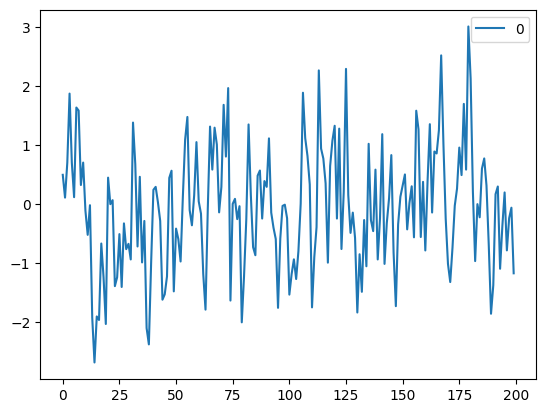

In [4]:
df.plot()

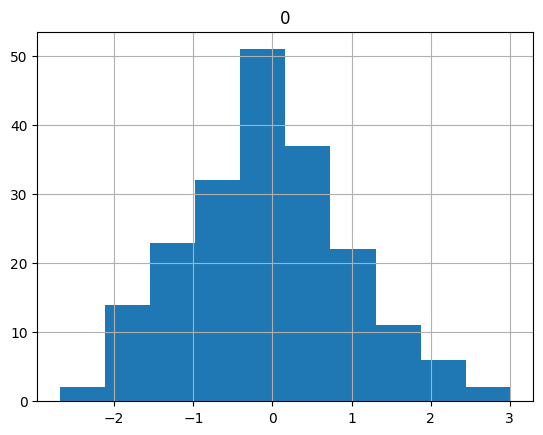

In [5]:
df.hist()
plt.show()

In [7]:
df['0'].skew()

0.13717912487475534

<Figure size 4000x1000 with 0 Axes>

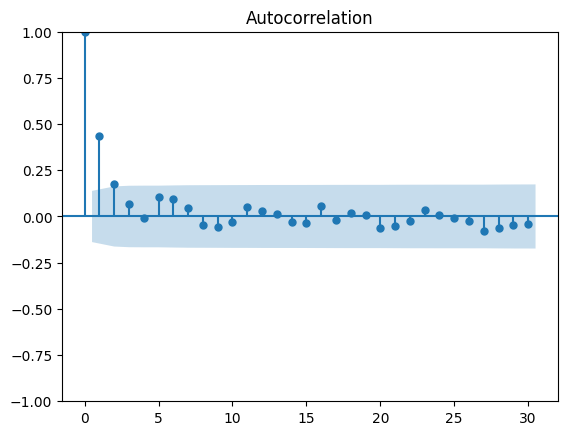

In [10]:
from statsmodels.graphics.tsaplots import plot_acf
plt.figure(figsize = (40,10))
plot_acf(df, lags=30)
plt.show()

# ARIMA MODELS

## AR model

In [35]:
from statsmodels.tsa.arima.model import ARIMA

In [36]:
#                        p,d,q
model = ARIMA(df, order=(1,0,0))
model_fitted = model.fit()
model_fitted.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      0   No. Observations:                  200
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -268.598
Date:                Thu, 18 Sep 2025   AIC                            543.196
Time:                        20:52:48   BIC                            553.091
Sample:                             0   HQIC                           547.200
                                - 200                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0777      0.117     -0.665      0.506      -0.307       0.151
ar.L1          0.4356      0.070      6.227      0.000       0.298       0.573
sigma2         0.8582      0.086      9.972      0.000       0.689       1.027
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):                 0.75
Prob(Q):                              0.90   Prob(JB):                         0.69
Heteroskedasticity (H):               0.97   Skew:                             0.15
Prob(H) (two-sided):                  0.92   Kurtosis:                         3.01
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [37]:
# errors of model
model_fitted.resid

0      0.574406
1     -0.062422
2      0.698629
3      1.612142
4     -0.069575
         ...   
195    0.405005
196   -0.827271
197    0.147015
198    0.086680
199   -1.103061
Length: 200, dtype: float64

In [38]:
rmse = np.sqrt(np.mean((model_fitted.resid)**2))
print("RMSE:",np.round(rmse,3))

RMSE: 0.927


## MA model

In [89]:
#                        p,q,d
model = ARIMA(df, order=(0,0,5))
model_fitted = model.fit()
model_fitted.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      0   No. Observations:                  200
Model:                 ARIMA(0, 0, 5)   Log Likelihood                -266.218
Date:                Thu, 18 Sep 2025   AIC                            546.435
Time:                        20:58:18   BIC                            569.524
Sample:                             0   HQIC                           555.779
                                - 200                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0773      0.114     -0.678      0.498      -0.301       0.146
ma.L1          0.4551      0.082      5.577      0.000       0.295       0.615
ma.L2          0.1809      0.092      1.968      0.049       0.001       0.361
ma.L3          0.1076      0.077      1.394      0.163      -0.044       0.259
ma.L4         -0.0862      0.086     -1.001      0.317      -0.255       0.083
ma.L5          0.0503      0.075      0.668      0.504      -0.097       0.198
sigma2         0.8374      0.085      9.821      0.000       0.670       1.005
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 1.96
Prob(Q):                              0.95   Prob(JB):                         0.38
Heteroskedasticity (H):               1.00   Skew:                             0.24
Prob(H) (two-sided):                  0.99   Kurtosis:                         3.10
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [90]:
# errors of model
model_fitted.resid

0      0.573994
1     -0.059847
2      0.706158
3      1.619012
4     -0.017187
         ...   
195    0.505804
196   -0.865551
197    0.007664
198    0.192438
199   -1.057229
Length: 200, dtype: float64

In [91]:
rmse = np.sqrt(np.mean((model_fitted.resid)**2))
print("RMSE:",np.round(rmse,3))

RMSE: 0.916


## ARIMA

In [92]:
#                        p,q,d
model = ARIMA(df, order=(2,1,5))
model_fitted = model.fit()
model_fitted.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      0   No. Observations:                  200
Model:                 ARIMA(2, 1, 5)   Log Likelihood                -267.504
Date:                Thu, 18 Sep 2025   AIC                            551.008
Time:                        20:59:05   BIC                            577.355
Sample:                             0   HQIC                           561.672
                                - 200                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3458      2.922     -0.118      0.906      -6.073       5.381
ar.L2          0.0274      1.608      0.017      0.986      -3.125       3.180
ma.L1         -0.1842      2.916     -0.063      0.950      -5.899       5.531
ma.L2         -0.4786      0.304     -1.577      0.115      -1.074       0.116
ma.L3         -0.1559      1.612     -0.097      0.923      -3.315       3.003
ma.L4         -0.2156      0.621     -0.347      0.729      -1.433       1.002
ma.L5          0.0571      0.670      0.085      0.932      -1.255       1.369
sigma2         0.8475      0.087      9.796      0.000       0.678       1.017
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 1.77
Prob(Q):                              0.98   Prob(JB):                         0.41
Heteroskedasticity (H):               1.02   Skew:                             0.23
Prob(H) (two-sided):                  0.94   Kurtosis:                         3.08
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [93]:
# errors of model
model_fitted.resid

0      0.496714
1     -0.386621
2      0.488005
3      1.284591
4     -0.657210
         ...   
195    0.469953
196   -0.907274
197   -0.023643
198    0.125832
199   -1.100030
Length: 200, dtype: float64

In [94]:
rmse = np.sqrt(np.mean((model_fitted.resid)**2))
print("RMSE:",np.round(rmse,3))

RMSE: 0.926


# Exponential Smoothing Tech

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing

### SMS

In [15]:
data = [3,10,12,13,12,10,12,14,13,15,16,18]
df = pd.DataFrame(data, columns=['Value'])
df

,Value
0,3
1,10
2,12
3,13
4,12
5,10
6,12
7,14
8,13
9,15


<Axes: >

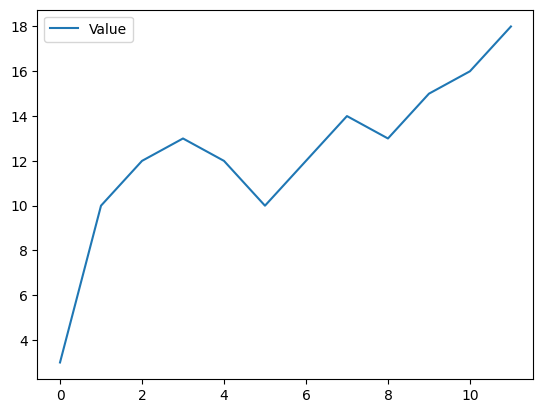

In [16]:
df.plot()

In [20]:
model = SimpleExpSmoothing(df['Value'])
# model_fitted = model.fit(smoothing_level=0.2, optimized=False) #---> to give alfa manually
model_fitted = model.fit(optimized=True) #--->auto chooses the alfa value/smooth value to reduse mse or rmse


In [21]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

2.5331140339287184

In [22]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 5)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0      3.0
1      3.0
2     10.0
3     12.0
4     13.0
5     12.0
6     10.0
7     12.0
8     14.0
9     13.0
10    15.0
11    16.0
dtype: float64
Forecasted values: 12    18.0
13    18.0
14    18.0
15    18.0
16    18.0
dtype: float64


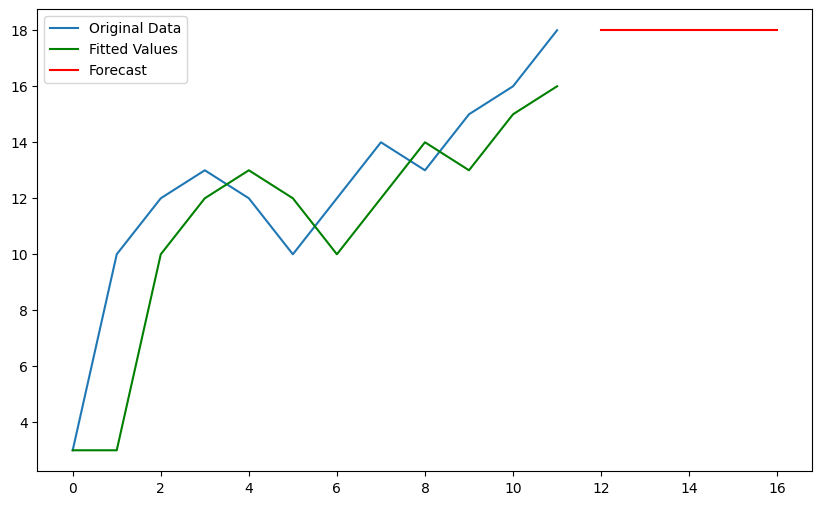

In [23]:
plt.figure(figsize=(10,6))
plt.plot(df['Value'], label = 'Original Data')
plt.plot(model_fitted.fittedvalues, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+5), forecast, label='Forecast', color='red')
plt.legend()
plt.show()

filure for future predections but got trained correctly

### holts linear

In [27]:
model = ExponentialSmoothing(df['Value'], trend = 'add', seasonal=None)
# model_fitted = model.fit(smoothing_level=0.8, smoothing_slope=0.2, optimized=False)
model_fitted = model.fit(optimized=True)

In [28]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

1.9820484320660268

In [29]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 5)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0      7.564103
1      8.431235
2      9.298368
3     10.165501
4     11.032634
5     11.899767
6     12.766900
7     13.634033
8     14.501166
9     15.368299
10    16.235431
11    17.102564
dtype: float64
Forecasted values: 12    17.969697
13    18.836830
14    19.703963
15    20.571096
16    21.438229
dtype: float64


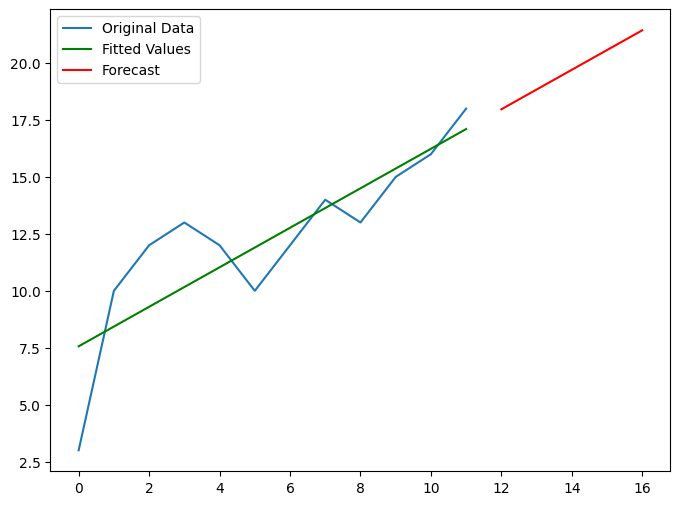

In [31]:
plt.figure(figsize=(8,6))
plt.plot(df['Value'], label = 'Original Data')
plt.plot(model_fitted.fittedvalues, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+5), forecast, label='Forecast', color='red')
plt.legend()
plt.show()

not good at past values observation but adjusted the future values  
so not good but rmse is better than SMS

### holt seasonal

In [46]:
model = ExponentialSmoothing(df['Value'], trend = 'add', seasonal='add', seasonal_periods=6)
# model_fitted = model.fit(smoothing_level=0.8, smoothing_slope=0.2, optimized=False)
model_fitted = model.fit(optimized=True)

In [47]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

1.4624940754643405

In [48]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 5)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0      5.166666
1      9.666663
2     10.166663
3     11.666665
4     11.666667
5     11.666670
6      9.833332
7     14.333329
8     14.833329
9     16.333331
10    16.333333
11    16.333336
dtype: float64
Forecasted values: 12    14.499997
13    18.999995
14    19.499995
15    20.999997
16    20.999999
dtype: float64


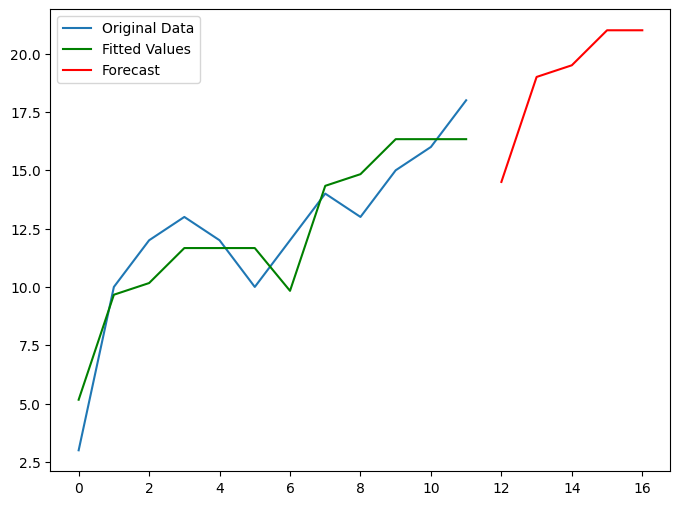

In [49]:
plt.figure(figsize=(8,6))
plt.plot(df['Value'], label = 'Original Data')
plt.plot(model_fitted.fittedvalues, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+5), forecast, label='Forecast', color='red')
plt.legend()
plt.show()